<a href="https://colab.research.google.com/github/nileve-teo/INSTRUMENTACION-BIOMEDICA/blob/main/Codificaci%C3%B3n03.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**Laboratorio N.° 3**:

Simulador de *sEMG*

**ETAPA A**

In [1]:
# ============================================
# LABORATORIO N.° 3 - ETAPA A
# Lectura de registros reales de sEMG - GRABMyo
# ============================================
!pip install wfdb

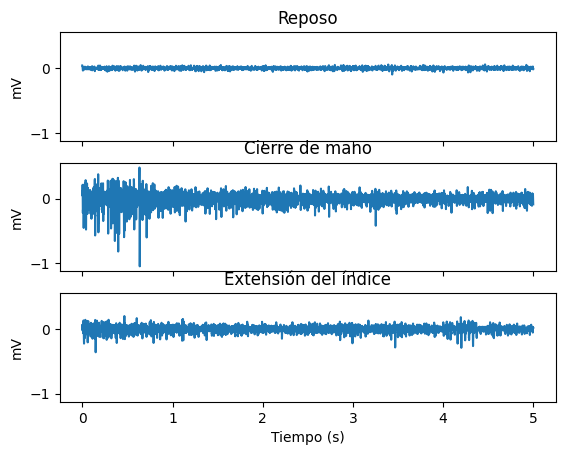

In [2]:

import wfdb
import numpy as np
import matplotlib.pyplot as plt

carpeta = "grabmyo/1.1.0/Session1/session1_participant1"

gestos = {
    "Reposo": 17,
    "Cierre de mano": 16,
    "Extensión del índice": 9
}

canal = 11  # canal F12 → índice 11 en Python

senales = {}

for nombre_g, k in gestos.items():
    rec = wfdb.rdrecord(
        f"session1_participant1_gesture{k}_trial1",
        pn_dir=carpeta
    )
    senales[nombre_g] = rec.p_signal[:, canal]

# ============================================
# GRÁFICAS DE LOS TRES REGISTROS
# ============================================

fig, ax = plt.subplots(3, 1, sharex=True, sharey=True)

for a, (nombre_g, x) in zip(ax, senales.items()):
    a.plot(np.arange(len(x)) / rec.fs, x)
    a.set_title(nombre_g)
    a.set_ylabel("mV")

ax[-1].set_xlabel("Tiempo (s)")

plt.show()

**ETAPA B** — Código para concatenar

In [3]:
print(senales.keys())

dict_keys(['Reposo', 'Cierre de mano', 'Extensión del índice'])


In [4]:
# ============================================
# ETAPA B - CONSTRUCCIÓN DE LA SECUENCIA
# ============================================

# Concatenar las señales en el orden indicado
secuencia = np.concatenate([
    senales["Reposo"],
    senales["Cierre de mano"],
    senales["Extensión del índice"]
])

# Verificar número de muestras
print("Número de muestras:", len(secuencia))

Número de muestras: 30720


In [5]:
# ============================================
# ESCALAMIENTO GLOBAL A 0 - 255
# ============================================

# Escalamiento lineal de toda la secuencia a valores entre 0 y 255

secuencia_escalada = ((secuencia - np.min(secuencia)) /
                      (np.max(secuencia) - np.min(secuencia)) * 255).astype(np.uint8)

print("Valor mínimo:", np.min(secuencia_escalada))
print("Valor máximo:", np.max(secuencia_escalada))

Valor mínimo: 0
Valor máximo: 255


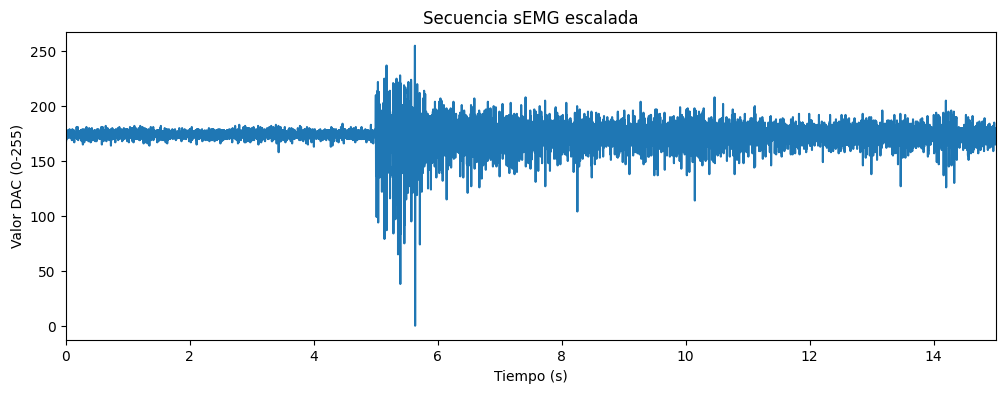

In [6]:
# ============================================
# GRÁFICA DE LA SECUENCIA ESCALADA
# ============================================

# Graficar la secuencia escalada

tiempo = np.arange(len(secuencia_escalada)) / 2048

plt.figure(figsize=(12, 4))
plt.plot(tiempo, secuencia_escalada)
plt.xlabel("Tiempo (s)")
plt.ylabel("Valor DAC (0-255)")
plt.title("Secuencia sEMG escalada")
plt.xlim(0, 15)
plt.show()

In [7]:
# ============================================
# GENERACIÓN DEL ARCHIVO semg.h
# ============================================

# Exportar la secuencia como semg.h

with open("semg.h", "w") as f:
    f.write("#include <stdint.h>\n\n")
    f.write("const uint8_t SEMG[] = {\n")

    for i in range(0, len(secuencia_escalada), 16):
        valores = secuencia_escalada[i:i+16]
        f.write("    " + ", ".join(map(str, valores)) + ",\n")

    f.write("};\n\n")
    f.write(f"const uint32_t N_SEMG = {len(secuencia_escalada)};\n")
    f.write("const uint32_t FS_SEMG = 2048;\n")

print("Archivo semg.h creado correctamente.")

Archivo semg.h creado correctamente.


Descargar semg.h

In [8]:
from google.colab import files

files.download("semg.h")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>